In [10]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [14]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = sns.load_dataset("taxis")
print("First 5 rows:")
print(df.head())
print("\nDataset information:")
print(df.info())
print("\nDataset shape:")
print(df.shape)

First 5 rows:
               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Si

In [18]:
print("\nMissing values before handling:")
print(df.isnull().sum())
# Convert pickup and dropoff columns to datetime
df["pickup"] = pd.to_datetime(df["pickup"], errors="coerce")
df["dropoff"] = pd.to_datetime(df["dropoff"], errors="coerce")
# Fill numerical missing values with median
numeric_columns = df.select_dtypes(include=np.number).columns
for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())
# Fill categorical missing values with mode
categorical_columns = df.select_dtypes(include=["object", "category"]).columns
for column in categorical_columns:
    if df[column].isnull().any():
        df[column] = df[column].fillna(df[column].mode()[0])
# Remove rows where pickup date is missing
df = df.dropna(subset=["pickup"])
print("\nMissing values after handling:")
print(df.isnull().sum())


Missing values before handling:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Missing values after handling:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


C:\Users\admin\AppData\Local\Temp\ipykernel_13440\3934358471.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=["object", "category"]).columns


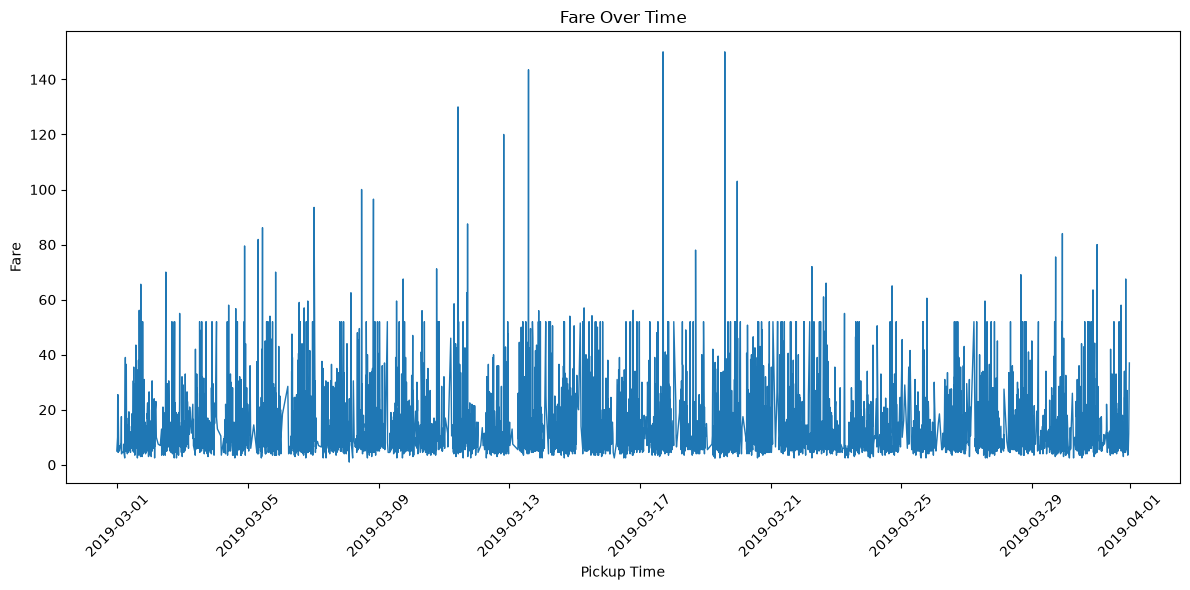

In [22]:
# Fare over time using pickup timestamp
df_line = df.sort_values("pickup")
plt.figure(figsize=(12, 6))
plt.plot(
    df_line["pickup"],
    df_line["fare"],
    linewidth=1
)
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

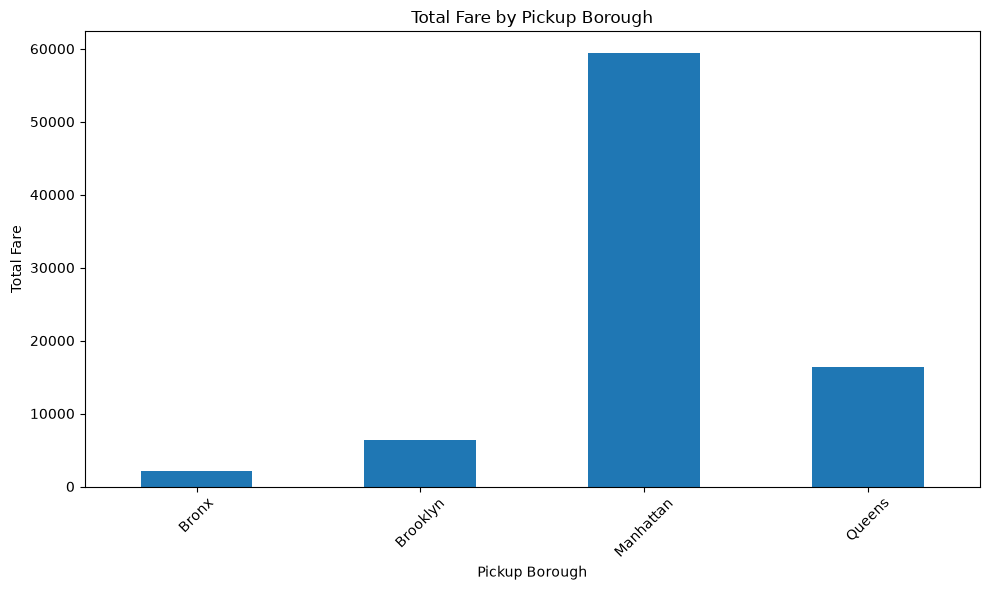

In [23]:
# Total fare for each pickup borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()
plt.figure(figsize=(10, 6))
borough_fare.plot(kind="bar")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

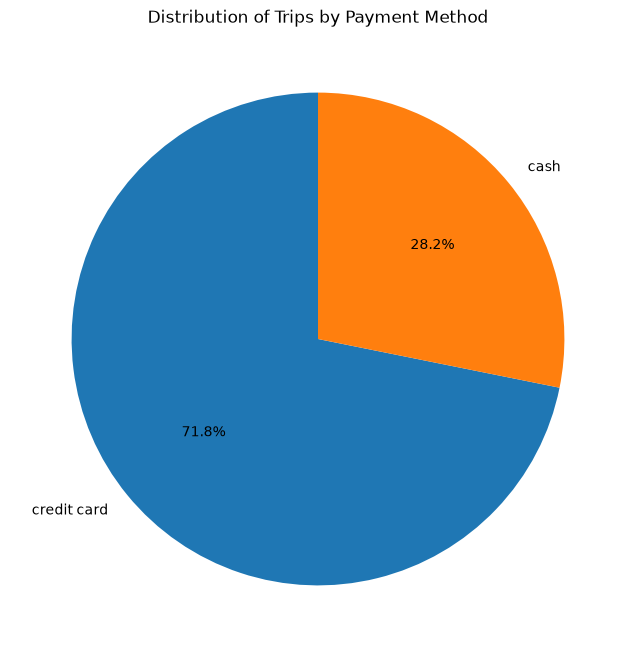

In [24]:
# Distribution of trips by payment method
payment_counts = df["payment"].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribution of Trips by Payment Method")
plt.show()

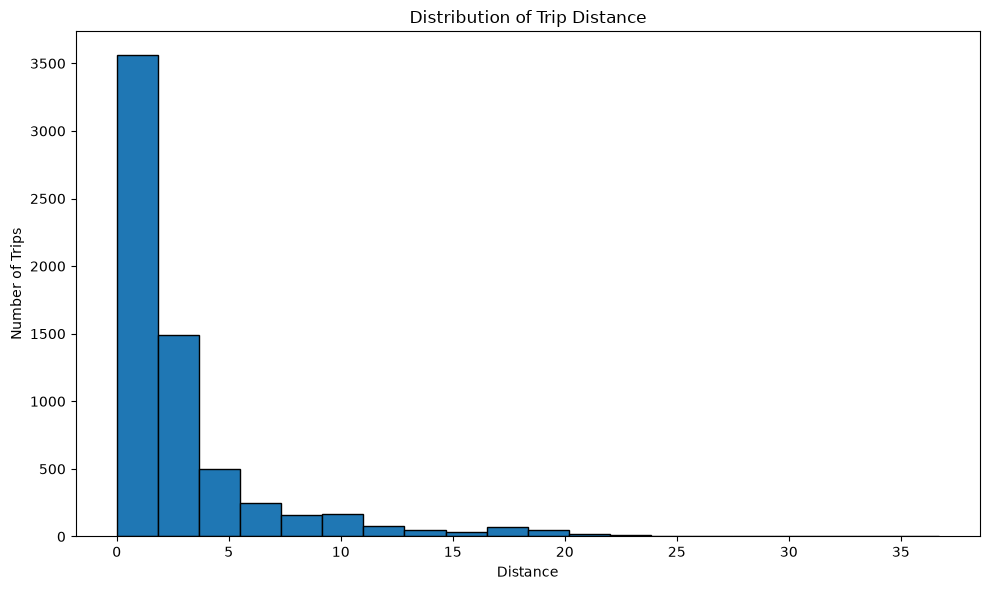

In [25]:
# Distribution of distance
plt.figure(figsize=(10, 6))
plt.hist(
    df["distance"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

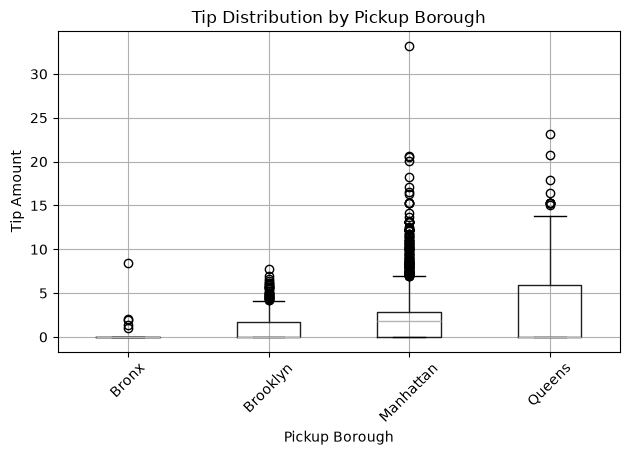

In [26]:
# Distribution of tip amounts for each pickup borough
plt.figure(figsize=(10, 6))

df.boxplot(
    column="tip",
    by="pickup_borough"
)
plt.title("Tip Distribution by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

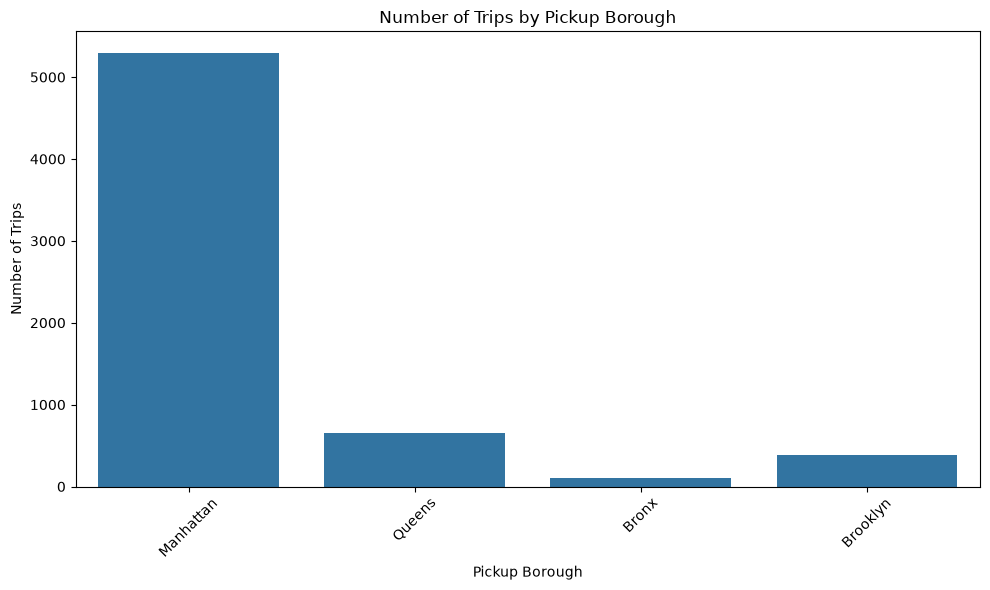

In [27]:
# Number of trips in each pickup borough
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x="pickup_borough"
)
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

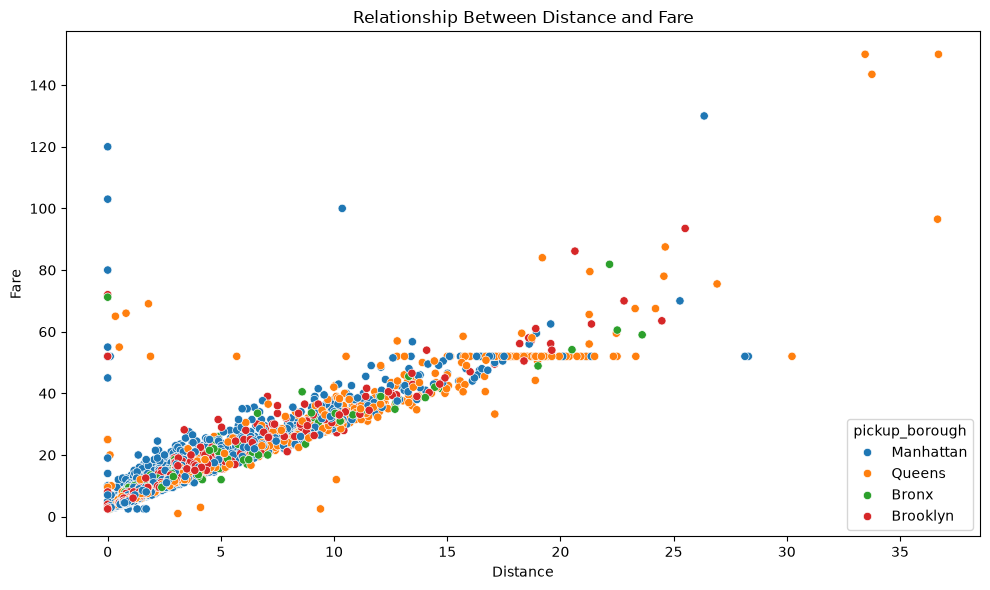

In [28]:
# Relationship between distance and fare
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

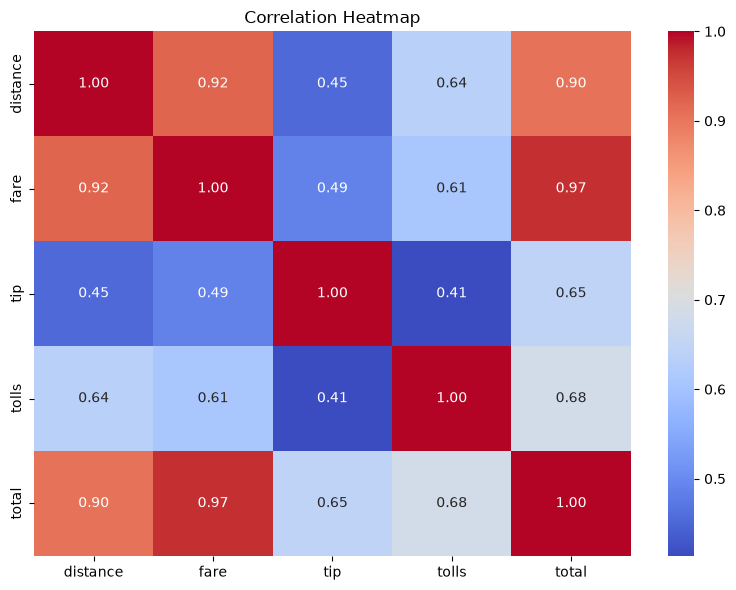

In [29]:
# Correlation between numerical variables
numeric_data = df[
    ["distance", "fare", "tip", "tolls", "total"]
]
correlation = numeric_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

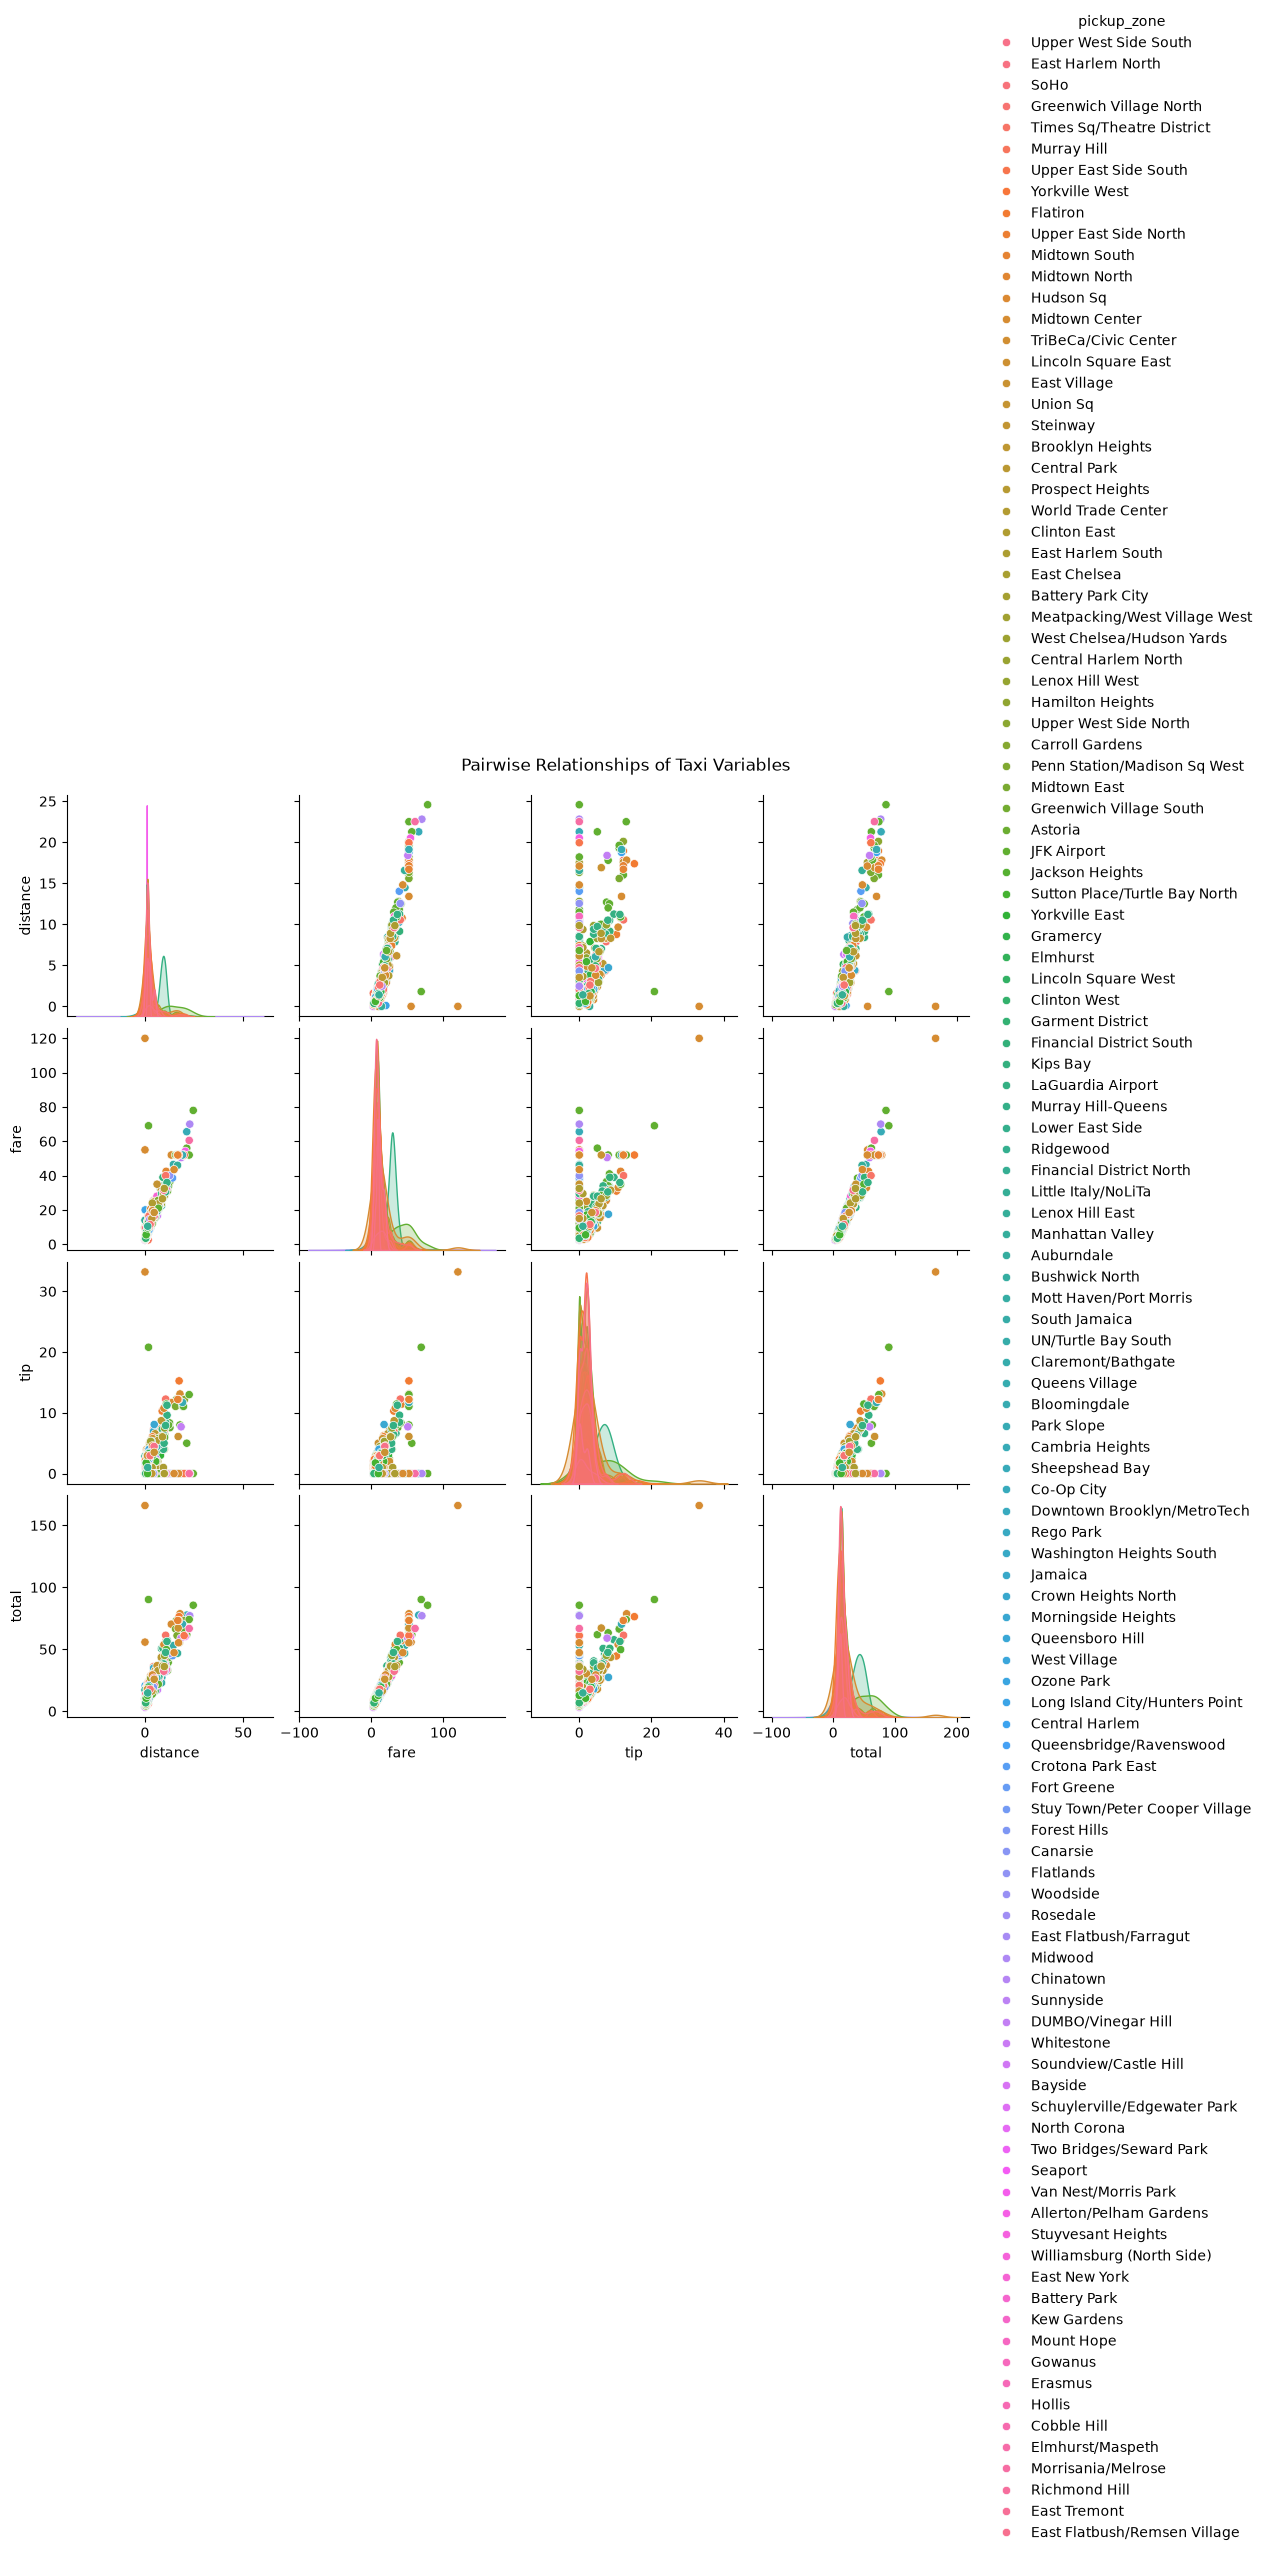

In [30]:
# Pairwise relationships
pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()
# To make the graph easier to handle, use a sample
pair_data = pair_data.sample(
    min(1000, len(pair_data)),
    random_state=42
)
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone"
)
plt.suptitle(
    "Pairwise Relationships of Taxi Variables",
    y=1.02
)
plt.show()

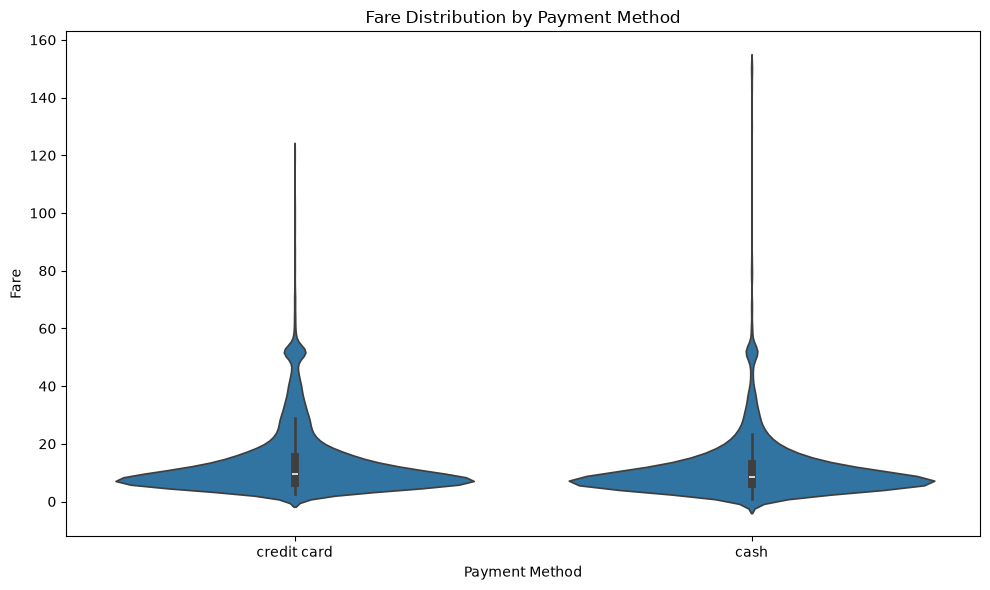

In [31]:
# Distribution of fare for each payment method
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)
plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()